### STUDENT DEPRESSION

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings("ignore")

In [2]:
path_file = r'Student_Depression_Dataset.csv'
df = pd.read_csv(path_file)
df.head(10)


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes
5,Female,24,Middle class,Single,Unmarried,Bachelor,9,3.80,Yes,Normal,17244,Chittagong,No
6,Female,21,Lower Middle class,Single,Unmarried,Family,9,3.50,Yes,Normal,1648,Dhaka,No
7,Female,19,Middle class,Single,Unmarried,Family,2,2.71,Yes,Abnormal,16782,Rajshahi,Yes
8,Female,21,Middle class,Single,Unmarried,Family,3,3.10,Yes,Abnormal,13386,Dhaka,Yes
9,Female,22,Middle class,In a Relationship,Married,Family,4,3.34,Yes,Normal,18131,Mymensingh,No


In [3]:
df.tail()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
4459,Female,26,Middle class,In a Relationship,Separated,Family,11,2.97,No,Critical,12619,Khulna,Yes
4460,Male,28,Lower Middle class,Single,Unmarried,Family,8,2.60,No,Normal,2806,Rajshahi,Yes
4461,Female,23,Middle class,In a Relationship,Married,Bachelor,10,2.80,No,Good,14066,Rajshahi,No
4462,Female,23,Middle class,Complicated,Married,Family,5,3.00,Yes,Normal,14338,Barisal,No
4463,Female,21,Lower Middle class,Single,Unmarried,Family,5,2.56,Yes,Abnormal,4000,Barisal,Yes


In [ ]:
df.columns

Index(['Gender', 'Age', 'Family_background', 'Relationship_status',
       'Marital_status', 'Living_style', 'Current_semester', 'CGPA',
       'friend_circle', 'Health_condition', 'Cost_without_study',
       'Home_division', 'Depression'],
      dtype='str')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 453.5 KB


Analisi missing values

In [5]:
df.isna().sum()

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

Analisi duplicati

In [6]:
df.duplicated().sum()

np.int64(0)

In [18]:
categorical_columns = [
    "Gender",
    "Family_background",
    "Relationship_status",
    "Marital_status",
    "Living_style",
    "Health_condition",
    "friend_circle",
    "Home_division"
]

# Data quality checks
print("Missing values per column:")
print(df.isna().sum())

print("\nUnique values per categorical column:")
for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

print("\nNumeric variables: potential impossible values")
print(df[["Age", "Current_semester", "CGPA", "Cost_without_study"]].agg(["min", "max"]))

# Coerenza logica: relazione e stato civile
print("\nRelationship status vs marital status:")
print(pd.crosstab(df["Relationship_status"], df["Marital_status"]))

Missing values per column:
Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

Unique values per categorical column:

Gender:
Gender
Female    2462
Male      2002
Name: count, dtype: int64

Family_background:
Family_background
Middle class          2642
Lower Middle class    1151
Rich class             671
Name: count, dtype: int64

Relationship_status:
Relationship_status
Single               2803
In a Relationship    1457
Complicated           204
Name: count, dtype: int64

Marital_status:
Marital_status
Unmarried    3619
Married       725
Separated     120
Name: count, dtype: int64

Living_style:
Living_style
Bachelor    2449
Family      2015
Name: count, dtype: int64

Health_condition:
Health_conditi

In [19]:
rare_categories = []

for col in categorical_columns:
    freq = df[col].value_counts(normalize=True)
    rare = freq[freq < 0.01]
    for category, proportion in rare.items():
        rare_categories.append({
            "Variable": col,
            "Category": category,
            "Count": int((df[col] == category).sum()),
            "Proportion": round(proportion * 100, 2)
        })

rare_categories = pd.DataFrame(rare_categories)
print(rare_categories)

Empty DataFrame
Columns: []
Index: []


### EXPLORATORY DATA ANALYSIS

In [7]:
# Dataset overview
total_students = len(df)

print(f"Total students: {total_students:,}")
print(f"Average age: {df['Age'].mean():.1f}")
print(f"Age range: {df['Age'].min()}–{df['Age'].max()}")
print(f"Number of semesters: {df['Current_semester'].nunique()}")

Total students: 4,464
Average age: 22.6
Age range: 17–28
Number of semesters: 14


In [ ]:
# descrittivo delle variabili numeriche
df.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


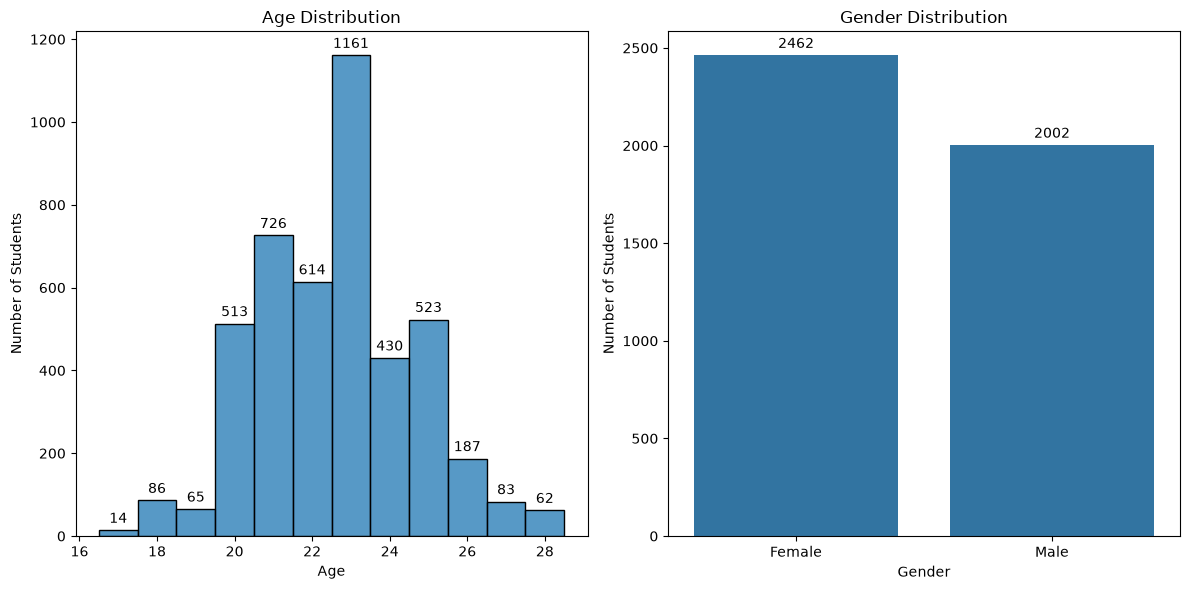

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Age Distribution
sns.histplot(
    data=df,
    x="Age",
    bins=12,
    discrete=True,
    ax=axes[0]
)
axes[0].set_title("Age Distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Number of Students")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=3)

# Gender Distribution
sns.countplot(
    data=df,
    x="Gender",
    ax=axes[1]
)
axes[1].set_title("Gender Distribution")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Number of Students")

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

Il campione presenta un'età compresa tra i 16 e i 28 anni, con la maggior parte della popolazione concentrata nella fascia 20-24. Risulta abbastanza bilanciato nella distribuzione del genere.

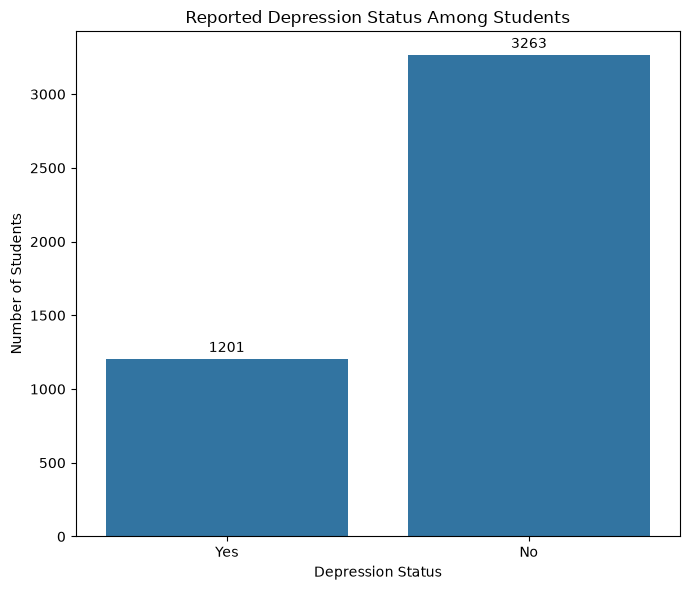

In [8]:
depression_counts = df["Depression"].value_counts()

depression_pct = (
    df["Depression"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

depression_summary = pd.DataFrame({
    "Count": depression_counts,
    "Percentage": depression_pct
})

plt.figure(figsize=(7, 6))

ax = sns.countplot(
    data=df,
    x="Depression"
)

# Add count labels above each bar
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

ax.set_title("Reported Depression Status Among Students")
ax.set_xlabel("Depression Status")
ax.set_ylabel("Number of Students")

plt.tight_layout()
plt.show()

Circa il 27% degli studenti si dichiara depresso.

In [ ]:
# funzione per visualizzare come si distribuiscono i predittori in base alla var. target  
def plot_depression_comparison(column, title, order=None):
    colors = {"No": "tab:blue", "Yes": "tab:orange"}

    # Define one consistent category order for both charts
    if order is None:
        order = df[column].value_counts().index.tolist()

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Count
    sns.countplot(
        data=df,
        x=column,
        hue="Depression",
        order=order,
        hue_order=["No", "Yes"],
        palette=colors,
        ax=axes[0]
    )

    axes[0].set_title(f"Number of students by {title} and Depression Status")
    axes[0].set_xlabel(title)
    axes[0].set_ylabel("Number of Students")
    axes[0].tick_params(axis="x", rotation=15)

    for container in axes[0].containers:
        axes[0].bar_label(
            container, fmt="%.0f", padding=3, fontsize=8
        )

    # Percentage
    pct = pd.crosstab(
        df[column], df["Depression"], normalize="index"
    ).mul(100).reindex(index=order, columns=["No", "Yes"], fill_value=0)

    pct.plot(
        kind="bar",
        color=[colors["No"], colors["Yes"]],
        ax=axes[1]
    )

    axes[1].set_title(f"Depression rate within each {title} (%)")
    axes[1].set_xlabel(title)
    axes[1].set_ylabel("Percentage of Students")
    axes[1].tick_params(axis="x", rotation=15)
    axes[1].legend(title="Depression Status")

    for container in axes[1].containers:
        axes[1].bar_label(
            container, fmt="%.1f%%", padding=3, fontsize=8
        )

    plt.tight_layout()
    plt.show()

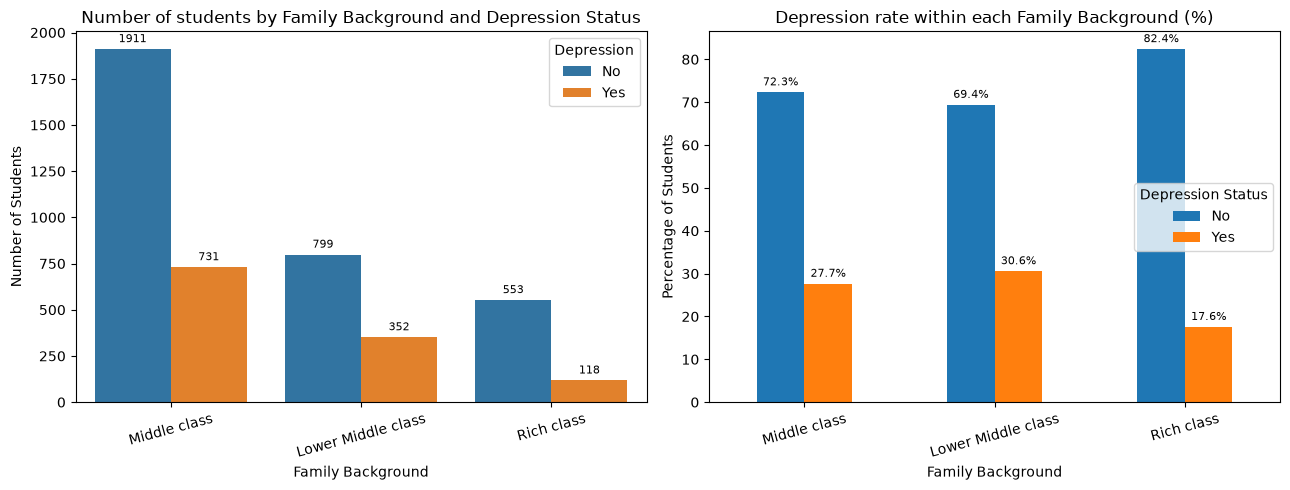

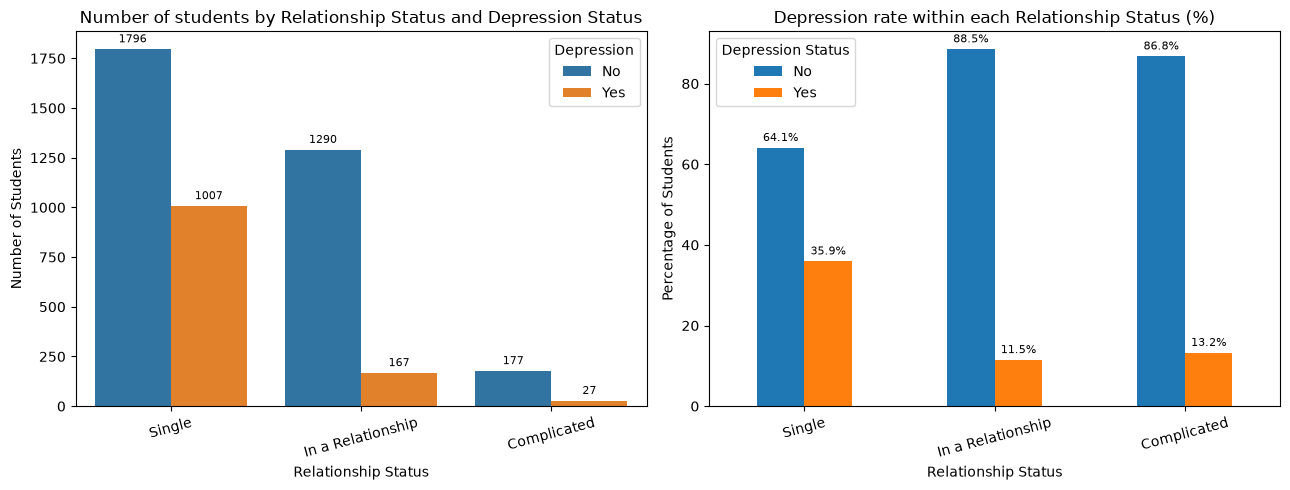

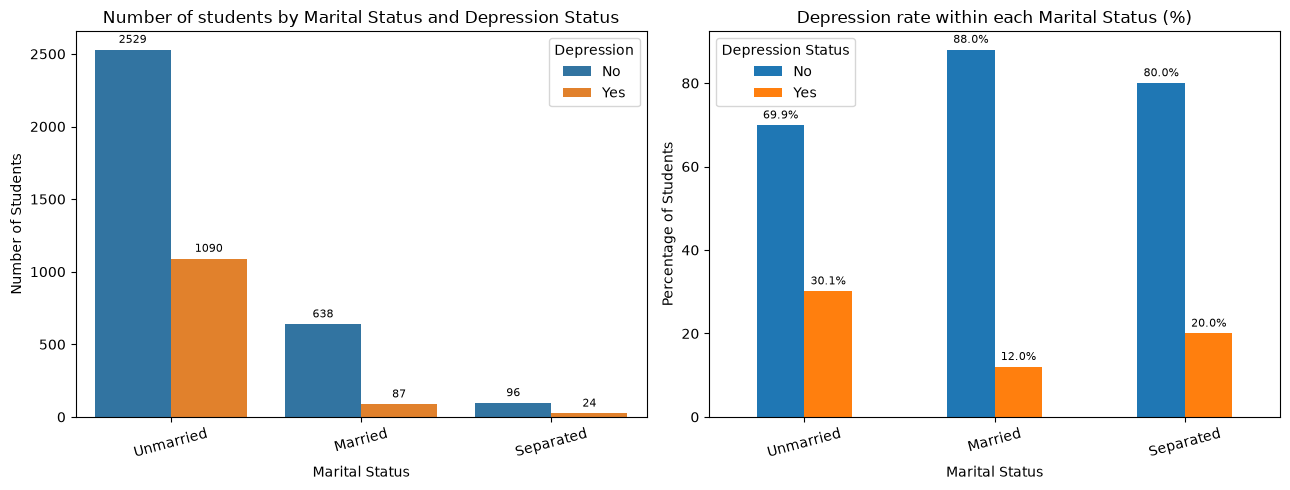

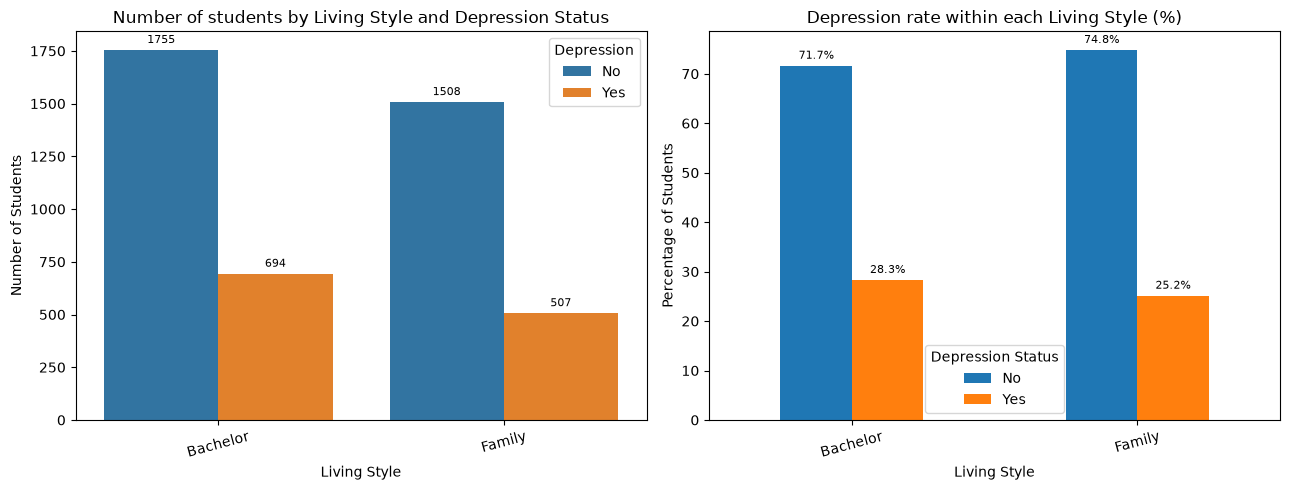

In [ ]:
#1 colonna da usare
#2 titolo
plot_depression_comparison("Family_background", "Family Background")
plot_depression_comparison("Relationship_status", "Relationship Status")
plot_depression_comparison("Marital_status", "Marital Status")
plot_depression_comparison("Living_style", "Living Style")

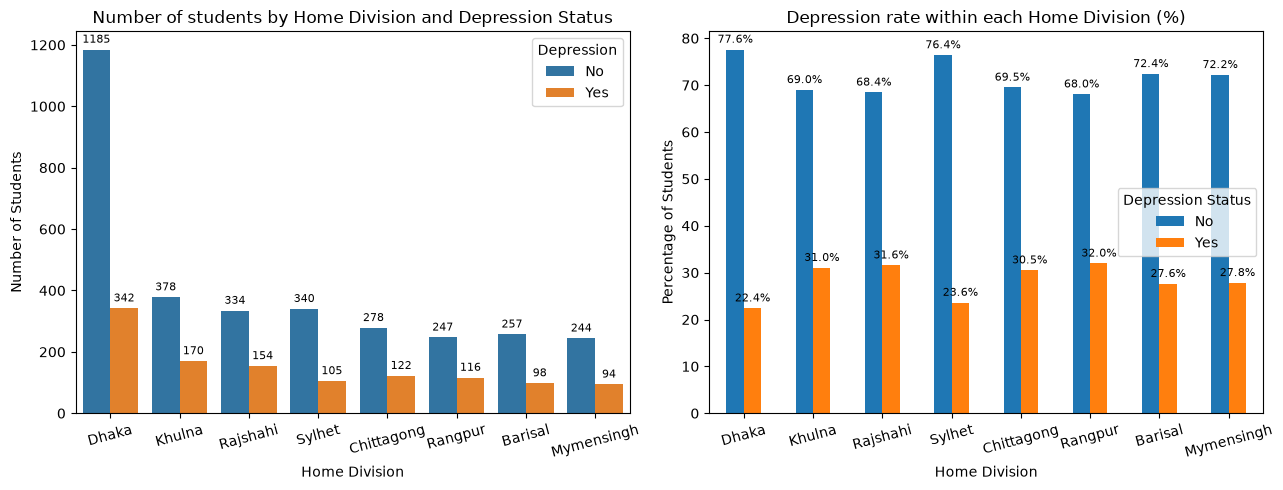

In [11]:
plot_depression_comparison("Home_division", "Home Division")


### DA ORDINARE

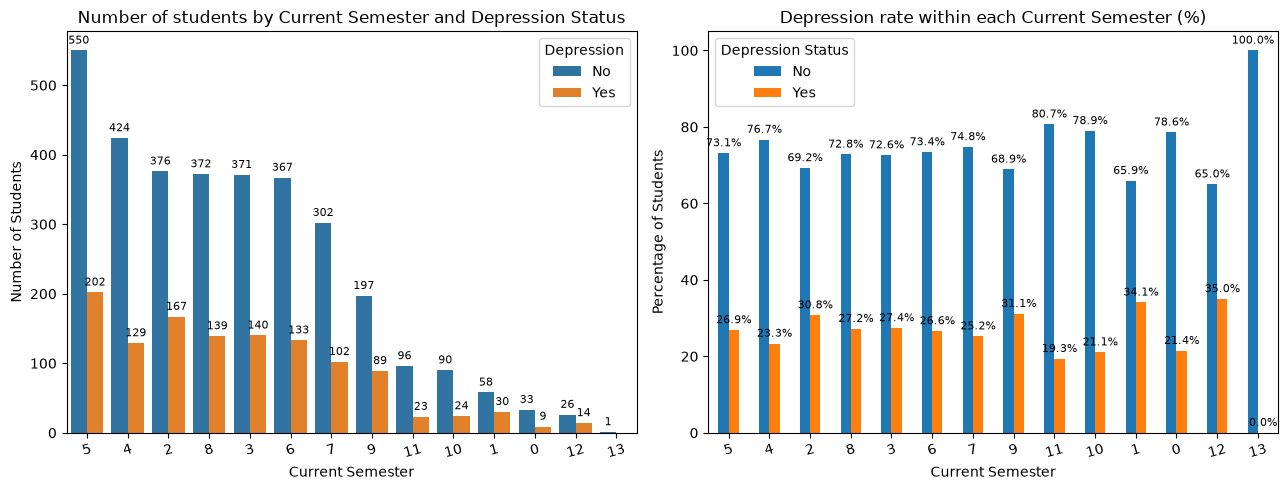

In [13]:
plot_depression_comparison("Current_semester", "Current Semester")

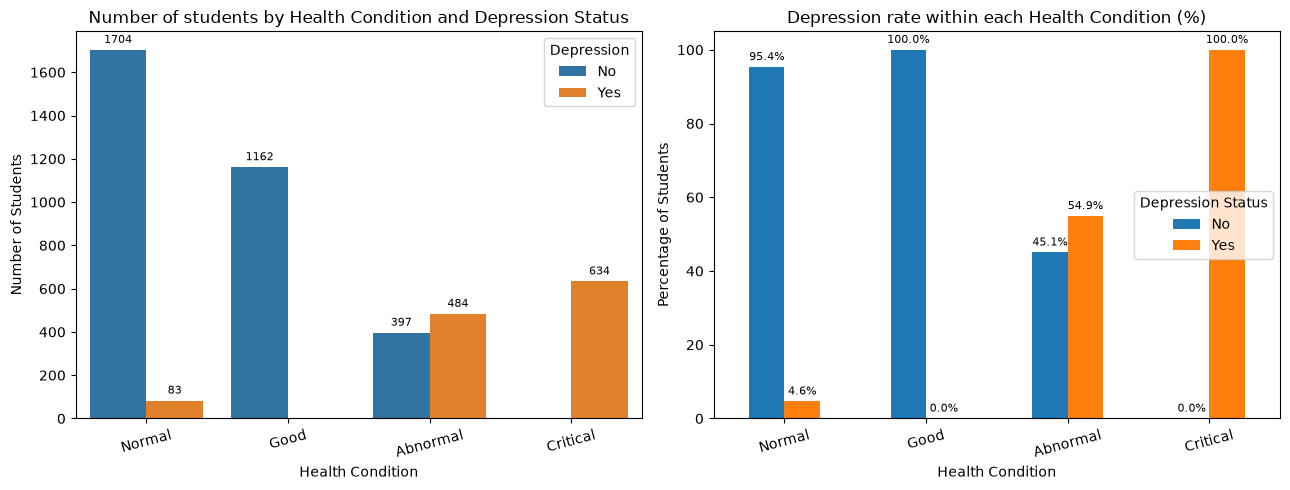

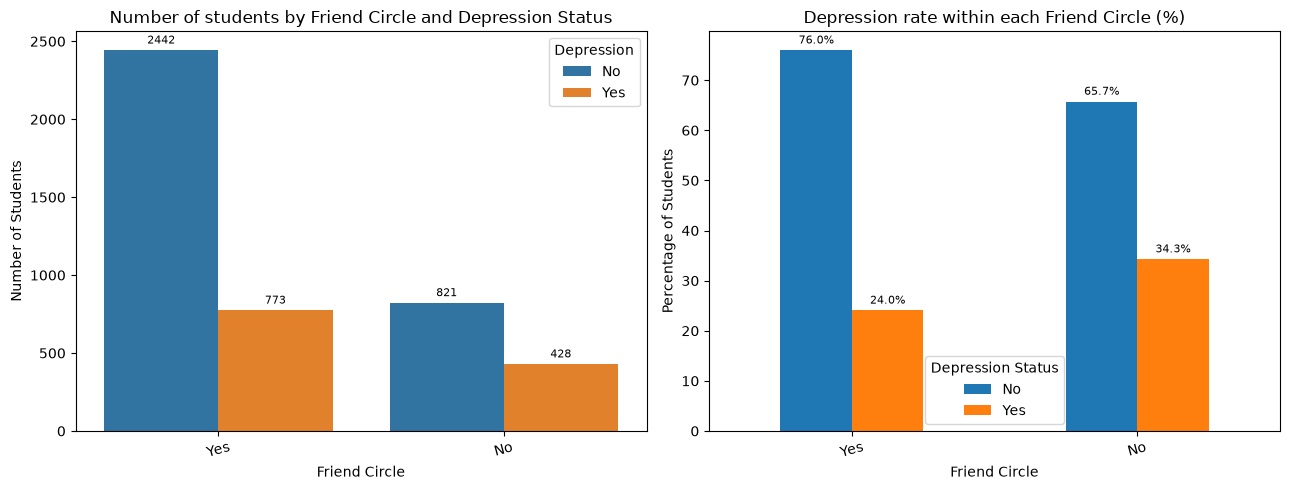

In [15]:
plot_depression_comparison("Health_condition", "Health Condition")
plot_depression_comparison("friend_circle", "Friend Circle")

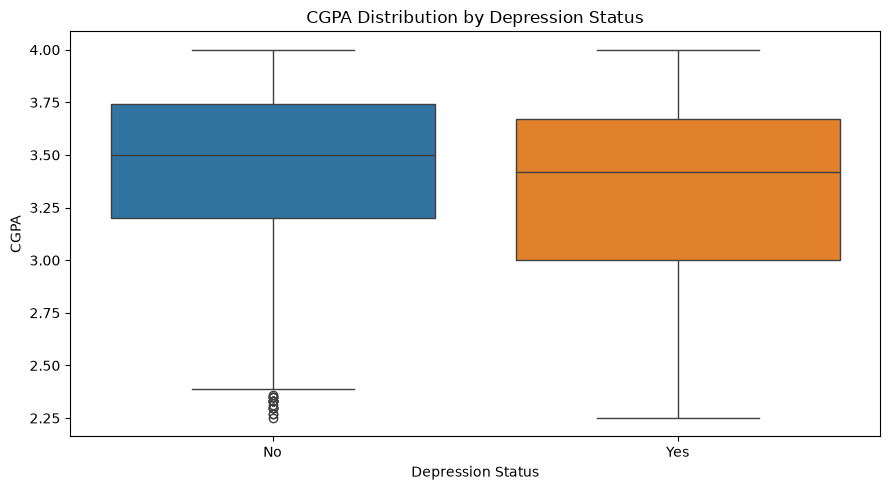

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Depression",
    y="CGPA",
    hue="Depression",
    order=["No", "Yes"],
    hue_order=["No", "Yes"],
    palette={"No": "tab:blue", "Yes": "tab:orange"},
    legend=False,
    ax=ax
)

ax.set_title("CGPA Distribution by Depression Status")
ax.set_xlabel("Depression Status")
ax.set_ylabel("CGPA")

plt.tight_layout()
plt.show()

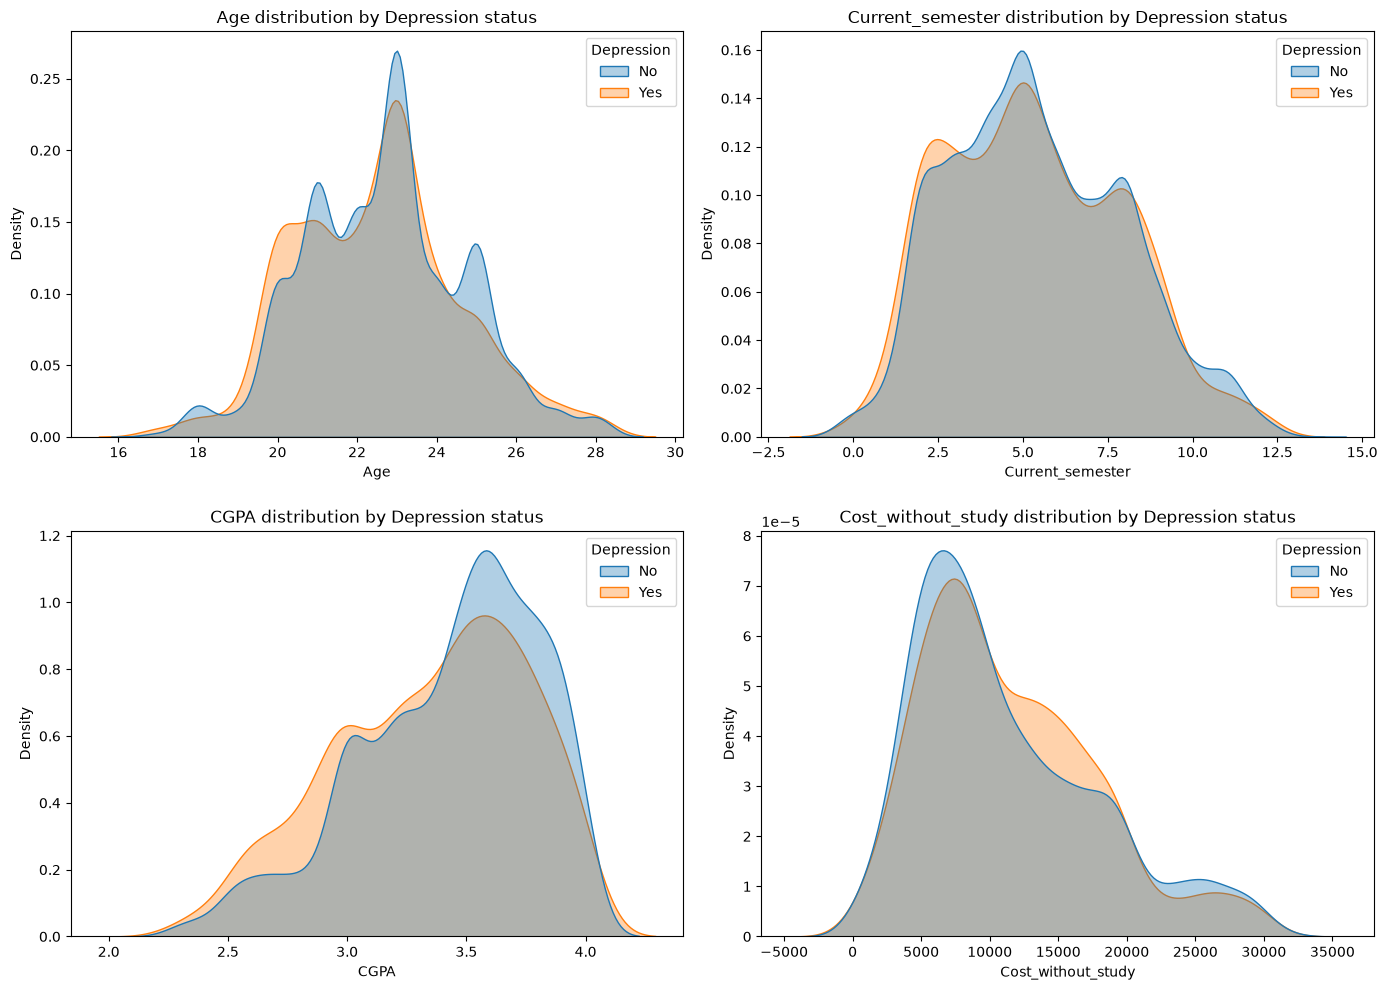

In [15]:
numeric_by_target = ["Age", "Current_semester", "CGPA", "Cost_without_study"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.ravel(), numeric_by_target):
    sns.kdeplot(
        data=df,
        x=col,
        hue="Depression",
        hue_order=["No", "Yes"],
        common_norm=False,
        fill=True,
        alpha=0.35,
        ax=ax
    )
    ax.set_title(f"{col} distribution by Depression status")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

In [16]:
numeric_summary = (
    df.groupby("Depression")[numeric_by_target]
    .agg(["mean", "median", "std", "min", "max"])
    .round(2)
)

print(numeric_summary)

              Age                      Current_semester                       \
             mean median   std min max             mean median   std min max   
Depression                                                                     
No          22.66   23.0  2.00  17  28             5.43    5.0  2.57   0  13   
Yes         22.51   23.0  2.07  17  28             5.33    5.0  2.60   0  12   

            CGPA                         Cost_without_study                    \
            mean median   std   min  max               mean   median      std   
Depression                                                                      
No          3.44   3.50  0.38  2.25  4.0           11169.58   9300.0  6737.38   
Yes         3.35   3.42  0.40  2.25  4.0           11442.40  10000.0  6366.92   

                       
           min    max  
Depression             
No           0  32000  
Yes          0  30634  


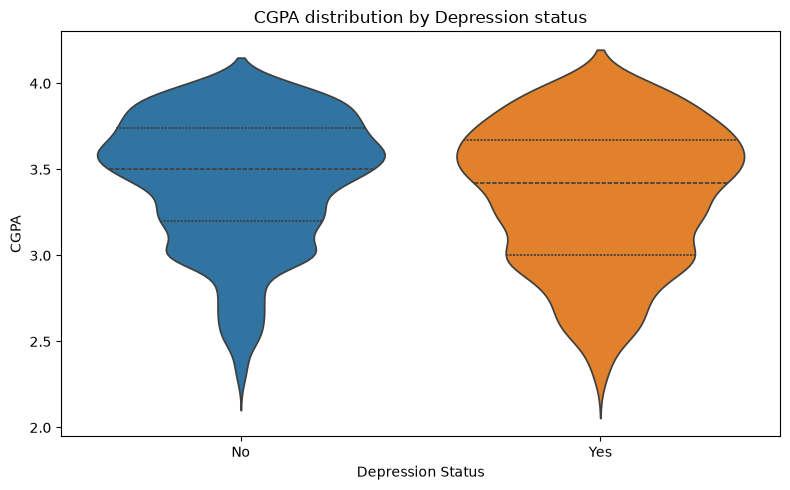

In [17]:
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x="Depression",
    y="CGPA",
    hue="Depression",
    order=["No", "Yes"],
    hue_order=["No", "Yes"],
    inner="quartile",
    palette={"No": "tab:blue", "Yes": "tab:orange"},
    legend=False
)

plt.title("CGPA distribution by Depression status")
plt.xlabel("Depression Status")
plt.ylabel("CGPA")
plt.tight_layout()
plt.show()

In [20]:
categorical_columns = [
    "Gender",
    "Family_background",
    "Relationship_status",
    "Marital_status",
    "Living_style",
    "Health_condition",
    "friend_circle",
    "Home_division"
]

summary_list = []

for col in categorical_columns:
    summary = (
        df.groupby(col, observed=True)["Depression"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .reset_index(name="Depression_Rate")
    )
    summary["Variable"] = col
    summary = summary.rename(columns={col: "Category"})
    summary_list.append(summary)

depression_rates = pd.concat(summary_list, ignore_index=True)

depression_rates = depression_rates[
    ["Variable", "Category", "Depression_Rate"]
].sort_values("Depression_Rate", ascending=False)

depression_rates["Depression_Rate"] = (
    depression_rates["Depression_Rate"].round(2)
)

print(depression_rates.to_string(index=False))
for col in categorical_columns:
    summary = (
        df.groupby(col, observed=True)["Depression"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .reset_index(name="Depression_Rate")
    )
    summary["Variable"] = col
    summary = summary.rename(columns={col: "Category"})
    summary_list.append(summary)

depression_rates = pd.concat(summary_list, ignore_index=True)

depression_rates = depression_rates[
    ["Variable", "Category", "Depression_Rate"]
].sort_values("Depression_Rate", ascending=False)

depression_rates["Depression_Rate"] = (
    depression_rates["Depression_Rate"].round(2)
)

print(depression_rates.to_string(index=False))
for col in categorical_columns:
    summary = (
        df.groupby(col, observed=True)["Depression"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .reset_index(name="Depression_Rate")
    )
    summary["Variable"] = col
    summary = summary.rename(columns={col: "Category"})
    summary_list.append(summary)

depression_rates = pd.concat(summary_list, ignore_index=True)

depression_rates = depression_rates[
    ["Variable", "Category", "Depression_Rate"]
].sort_values("Depression_Rate", ascending=False)

depression_rates["Depression_Rate"] = (
    depression_rates["Depression_Rate"].round(2)
)

print(depression_rates.to_string(index=False))

           Variable           Category  Depression_Rate
   Health_condition           Critical           100.00
   Health_condition           Abnormal            54.94
Relationship_status             Single            35.93
      friend_circle                 No            34.27
      Home_division            Rangpur            31.96
      Home_division           Rajshahi            31.56
      Home_division             Khulna            31.02
  Family_background Lower Middle class            30.58
      Home_division         Chittagong            30.50
     Marital_status          Unmarried            30.12
       Living_style           Bachelor            28.34
      Home_division         Mymensingh            27.81
  Family_background       Middle class            27.67
      Home_division            Barisal            27.61
             Gender               Male            27.27
             Gender             Female            26.60
       Living_style             Family          

In [21]:
from scipy.stats import chi2_contingency
import numpy as np

association_results = []

for col in categorical_columns:
    contingency_table = pd.crosstab(df[col], df["Depression"])

    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    n = contingency_table.to_numpy().sum()
    r, k = contingency_table.shape

    denominator = n * min(r - 1, k - 1)
    cramers_v = np.sqrt(chi2 / denominator) if denominator > 0 else np.nan

    association_results.append({
        "Variable": col,
        "Chi-square": round(chi2, 2),
        "Degrees of Freedom": dof,
        "P-value": p_value,
        "Cramer's V": round(cramers_v, 3),
    })

association_table = pd.DataFrame(association_results)

association_table["P-value"] = association_table["P-value"].map(
    lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"
)

print(association_table.to_string(index=False))

           Variable  Chi-square  Degrees of Freedom P-value  Cramer's V
             Gender        0.22                   1   0.641       0.007
  Family_background       38.33                   2 < 0.001       0.093
Relationship_status      312.06                   2 < 0.001       0.264
     Marital_status      103.82                   2 < 0.001       0.153
       Living_style        5.51                   1   0.019       0.035
   Health_condition     2952.51                   3 < 0.001       0.813
      friend_circle       47.29                   1 < 0.001       0.103
      Home_division       35.92                   7 < 0.001       0.090


In [22]:
for col in categorical_columns:
    table = pd.crosstab(df[col], df["Depression"])
    chi2, p_value, dof, expected = chi2_contingency(table)

    expected_df = pd.DataFrame(
        expected,
        index=table.index,
        columns=table.columns
    ).round(1)

    print(f"\n### {col}")
    print("Observed counts:")
    print(table)
    print("\nExpected counts:")
    print(expected_df)


### Gender
Observed counts:
Depression    No  Yes
Gender               
Female      1807  655
Male        1456  546

Expected counts:
Depression      No    Yes
Gender                   
Female      1799.6  662.4
Male        1463.4  538.6

### Family_background
Observed counts:
Depression            No  Yes
Family_background            
Lower Middle class   799  352
Middle class        1911  731
Rich class           553  118

Expected counts:
Depression              No    Yes
Family_background                
Lower Middle class   841.3  309.7
Middle class        1931.2  710.8
Rich class           490.5  180.5

### Relationship_status
Observed counts:
Depression             No   Yes
Relationship_status            
Complicated           177    27
In a Relationship    1290   167
Single               1796  1007

Expected counts:
Depression               No    Yes
Relationship_status               
Complicated           149.1   54.9
In a Relationship    1065.0  392.0
Single               20

In [23]:
category_quality = []

for col in categorical_columns:
    counts = df[col].value_counts()
    category_quality.append({
        "Variable": col,
        "N categories": df[col].nunique(),
        "Smallest category": counts.idxmin(),
        "Smallest count": counts.min(),
        "Smallest proportion (%)": round(counts.min() / len(df) * 100, 2)
    })

print(pd.DataFrame(category_quality).to_string(index=False))

           Variable  N categories Smallest category  Smallest count  Smallest proportion (%)
             Gender             2              Male            2002                    44.85
  Family_background             3        Rich class             671                    15.03
Relationship_status             3       Complicated             204                     4.57
     Marital_status             3         Separated             120                     2.69
       Living_style             2            Family            2015                    45.14
   Health_condition             4          Critical             634                    14.20
      friend_circle             2                No            1249                    27.98
      Home_division             8        Mymensingh             338                     7.57


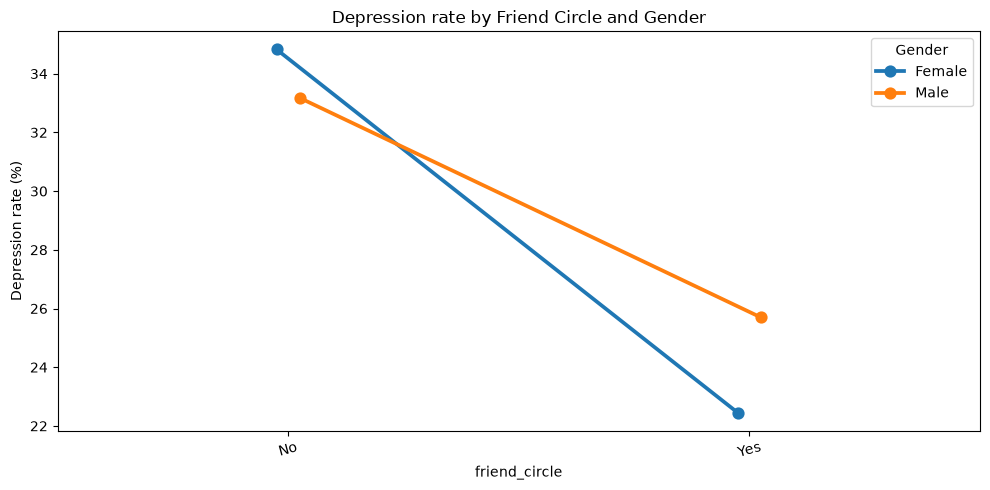

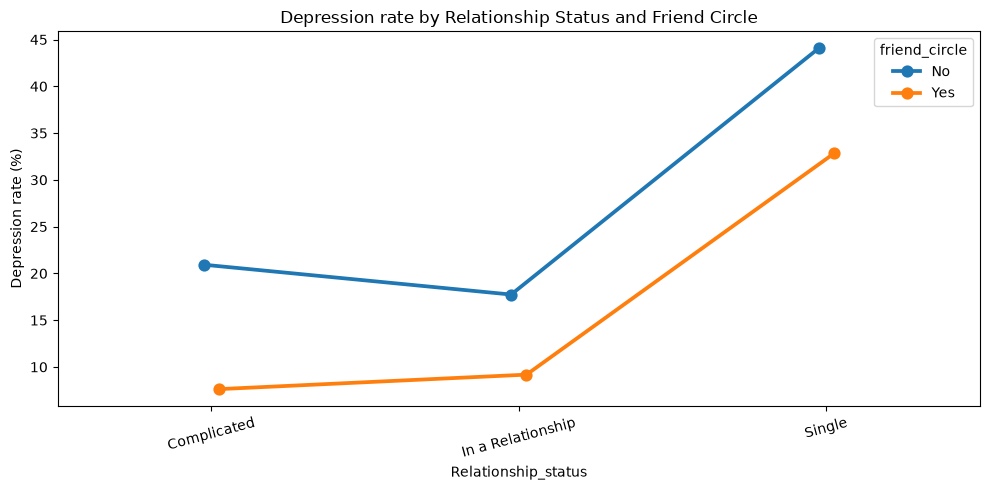

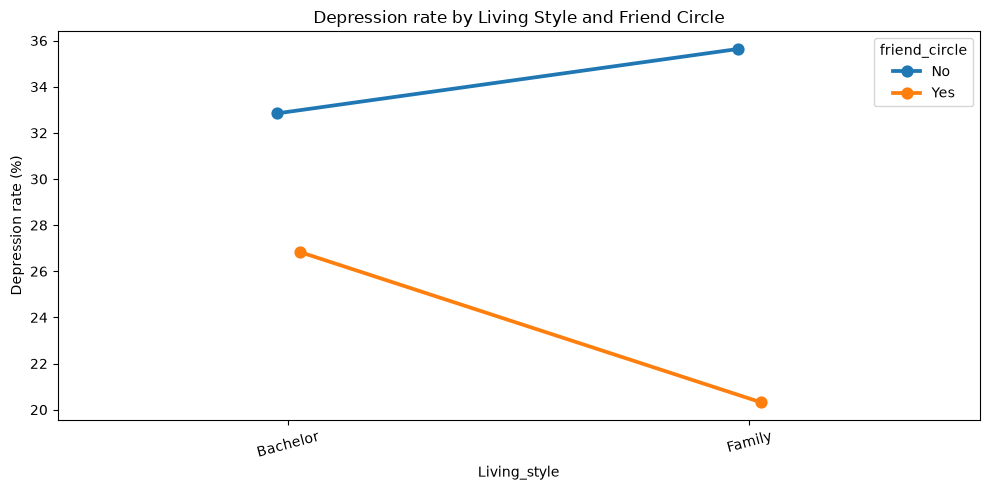

In [29]:
def plot_interaction_rate(row_var, col_var, title):
    rate = (
        df.groupby([row_var, col_var], observed=True)["Depression"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .reset_index(name="Depression_Rate")
    )

    plt.figure(figsize=(10, 5))

    sns.pointplot(
        data=rate,
        x=row_var,
        y="Depression_Rate",
        hue=col_var,
        dodge=True,
        markers="o",
        linestyles="-"
    )

    plt.title(title)
    plt.xlabel(row_var)
    plt.ylabel("Depression rate (%)")
    plt.legend(title=col_var)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()


plot_interaction_rate(
    "friend_circle",
    "Gender",
    "Depression rate by Friend Circle and Gender"
)


plot_interaction_rate(
    "Relationship_status",
    "friend_circle",
    "Depression rate by Relationship Status and Friend Circle"
)

plot_interaction_rate(
    "Living_style",
    "friend_circle",
    "Depression rate by Living Style and Friend Circle"
)

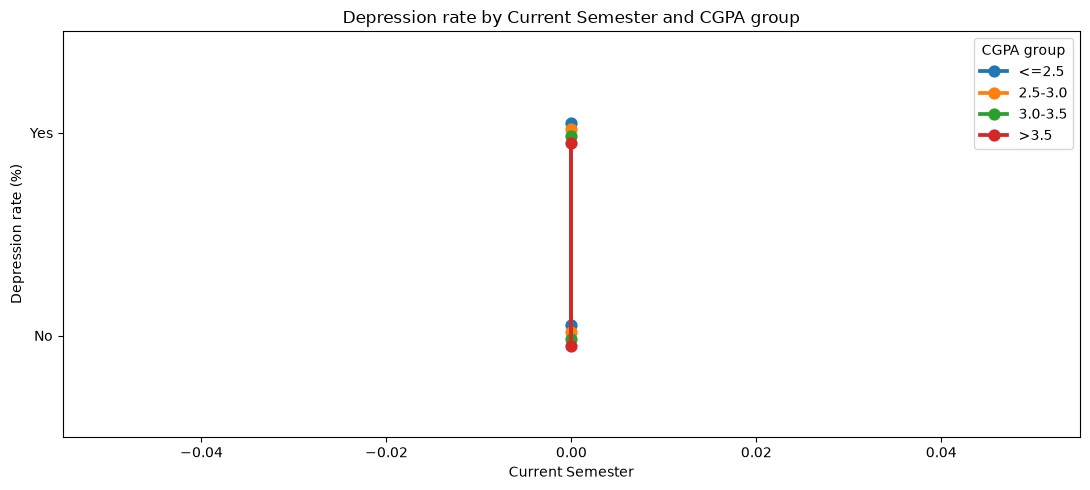

In [25]:
df["CGPA_group"] = pd.cut(
    df["CGPA"],
    bins=[0, 2.5, 3.0, 3.5, 4.0],
    labels=["<=2.5", "2.5-3.0", "3.0-3.5", ">3.5"],
    include_lowest=True
)

plt.figure(figsize=(11, 5))

sns.pointplot(
    data=df,
    x="Current_semester",
    y="Depression",
    hue="CGPA_group",
    estimator=lambda x: (x == "Yes").mean() * 100,
    errorbar=("ci", 95),
    dodge=True
)

plt.title("Depression rate by Current Semester and CGPA group")
plt.xlabel("Current Semester")
plt.ylabel("Depression rate (%)")
plt.legend(title="CGPA group")
plt.tight_layout()
plt.show()

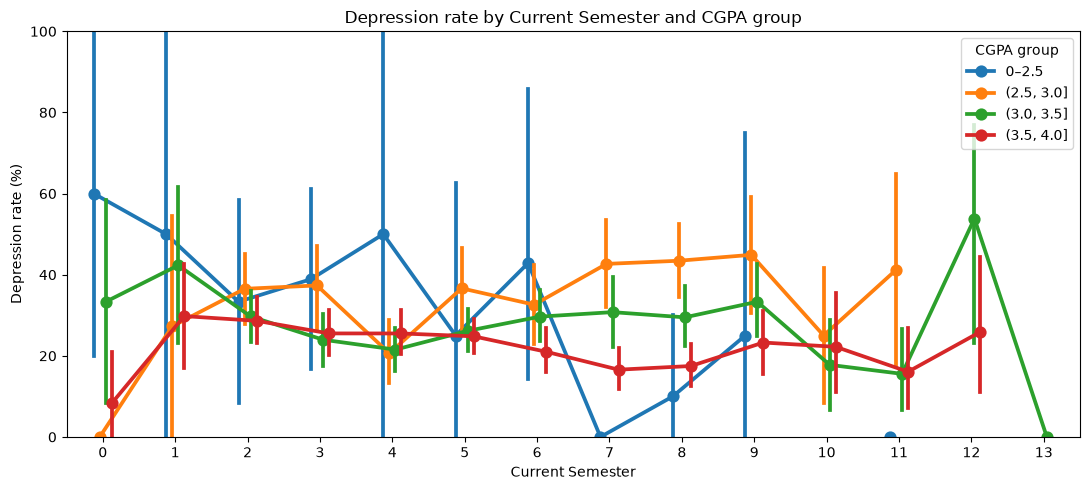

In [30]:
d = df.copy()

# Yes → 1; No → 0; eventuali valori mancanti restano mancanti
d["Depression_bin"] = d["Depression"].map({
    "Yes": 1,
    "No": 0
})

# Fasce di CGPA
labels = ["0–2.5", "(2.5, 3.0]", "(3.0, 3.5]", "(3.5, 4.0]"]

d["CGPA_group"] = pd.cut(
    d["CGPA"],
    bins=[0, 2.5, 3.0, 3.5, 4.0],
    labels=labels,
    include_lowest=True,
    right=True
)

# Mantieni solo i record completi per le variabili utilizzate
plot_df = d.dropna(
    subset=["Current_semester", "CGPA_group", "Depression_bin"]
).copy()

# La media di questa colonna restituisce una percentuale
plot_df["Depression_pct"] = plot_df["Depression_bin"] * 100

plt.figure(figsize=(11, 5))

sns.pointplot(
    data=plot_df,
    x="Current_semester",
    y="Depression_pct",
    hue="CGPA_group",
    hue_order=labels,
    estimator="mean",
    errorbar=("ci", 95),
    n_boot=2000,
    seed=42,
    dodge=0.25
)

plt.title("Depression rate by Current Semester and CGPA group")
plt.xlabel("Current Semester")
plt.ylabel("Depression rate (%)")
plt.ylim(0, 100)
plt.legend(title="CGPA group")
plt.tight_layout()
plt.show()

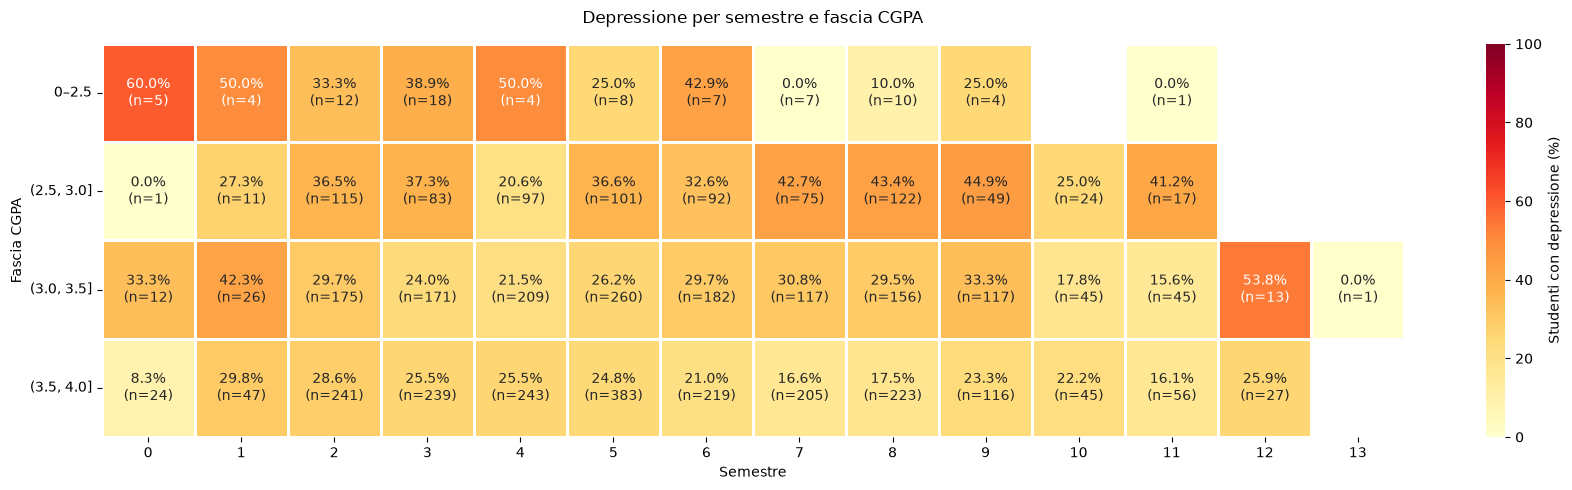

In [31]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

d = df.copy()

d["Depression_bin"] = d["Depression"].map({
    "Yes": 1,
    "No": 0
})

labels = ["0–2.5", "(2.5, 3.0]", "(3.0, 3.5]", "(3.5, 4.0]"]

d["CGPA_group"] = pd.cut(
    d["CGPA"],
    bins=[0, 2.5, 3.0, 3.5, 4.0],
    labels=labels,
    include_lowest=True
)

d = d.dropna(
    subset=["Current_semester", "CGPA_group", "Depression_bin"]
)

# Percentuale e numerosità per ogni combinazione
summary = (
    d.groupby(
        ["CGPA_group", "Current_semester"],
        observed=True
    )
    .agg(
        rate=("Depression_bin", "mean"),
        n=("Depression_bin", "size")
    )
    .reset_index()
)

summary["rate"] *= 100

rates = summary.pivot(
    index="CGPA_group",
    columns="Current_semester",
    values="rate"
).reindex(labels)

counts = summary.pivot(
    index="CGPA_group",
    columns="Current_semester",
    values="n"
).reindex(index=rates.index, columns=rates.columns)

# Ordine numerico dei semestri, anche se memorizzati come "1", "2", ...
# Per etichette come "Semester 1", specificare manualmente l'ordine.
try:
    semester_order = sorted(rates.columns, key=float)
except (ValueError, TypeError):
    semester_order = list(rates.columns)

rates = rates.reindex(columns=semester_order)
counts = counts.reindex(columns=semester_order)

# Testo nelle celle
annotations = pd.DataFrame(
    "",
    index=rates.index,
    columns=rates.columns
)

for row in rates.index:
    for col in rates.columns:
        if pd.notna(rates.loc[row, col]):
            annotations.loc[row, col] = (
                f"{rates.loc[row, col]:.1f}%\n"
                f"(n={int(counts.loc[row, col])})"
            )

fig, ax = plt.subplots(
    figsize=(max(9, 1.25 * len(rates.columns)), 5)
)

sns.heatmap(
    rates,
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.8,
    linecolor="white",
    annot_kws={"fontsize": 10},
    cbar_kws={"label": "Studenti con depressione (%)"},
    ax=ax
)

ax.set_title("Depressione per semestre e fascia CGPA", pad=15)
ax.set_xlabel("Semestre")
ax.set_ylabel("Fascia CGPA")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

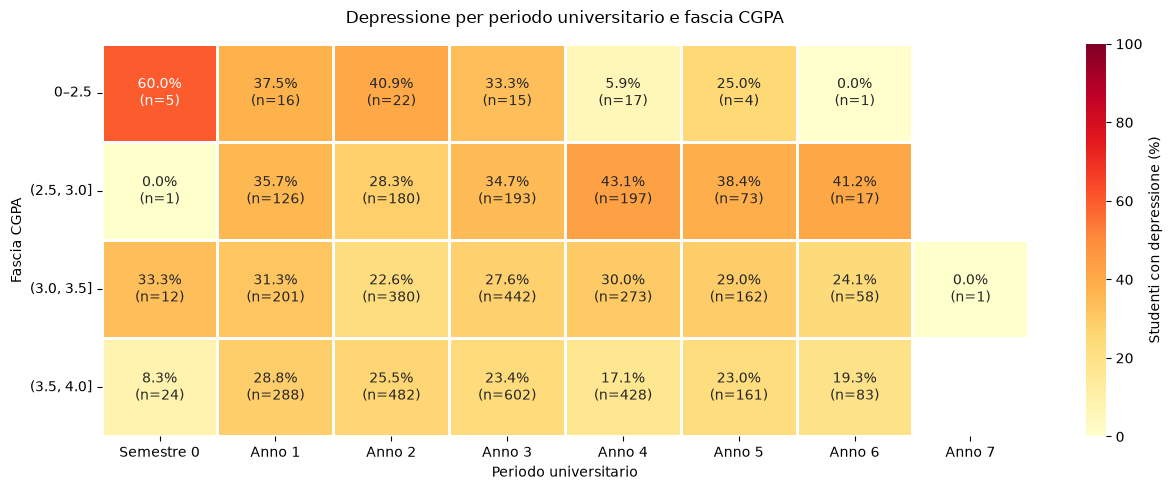

In [49]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

d = df.copy()

# Target: Yes → 1, No → 0
d["Depression_bin"] = d["Depression"].map({
    "Yes": 1,
    "No": 0
})

# Conversione delle variabili in numerico
d["Current_semester"] = pd.to_numeric(
    d["Current_semester"],
    errors="raise"
)
d["CGPA"] = pd.to_numeric(d["CGPA"], errors="raise")

# Verifica che i semestri siano interi non negativi
semester = d["Current_semester"].dropna()

if ((semester < 0) | (semester % 1 != 0)).any():
    raise ValueError(
        "Current_semester deve contenere numeri interi non negativi."
    )

# Verifica della scala CGPA
if not d["CGPA"].dropna().between(0, 4).all():
    raise ValueError(
        "CGPA contiene valori fuori dall'intervallo 0–4."
    )

# Raggruppamento:
# semestre 0 → gruppo 0, visualizzato come "Semestre 0"
# semestri 1–2 → anno 1
# semestri 3–4 → anno 2
# semestri 5–6 → anno 3
# ...
d["University_year"] = (
    (d["Current_semester"] + 1) // 2
).astype("Int64")

# Fasce di CGPA
labels = ["0–2.5", "(2.5, 3.0]", "(3.0, 3.5]", "(3.5, 4.0]"]

d["CGPA_group"] = pd.cut(
    d["CGPA"],
    bins=[0, 2.5, 3.0, 3.5, 4.0],
    labels=labels,
    include_lowest=True,
    right=True
)

# Esclusione dei record mancanti nelle variabili utilizzate
d = d.dropna(
    subset=["University_year", "CGPA_group", "Depression_bin"]
)

if d.empty:
    raise ValueError(
        "Nessuna osservazione disponibile dopo i filtri."
    )

# Percentuale e numerosità per combinazione
summary = (
    d.groupby(
        ["CGPA_group", "University_year"],
        observed=True
    )
    .agg(
        rate=("Depression_bin", "mean"),
        n=("Depression_bin", "size")
    )
    .reset_index()
)

summary["rate"] *= 100

# Matrice delle percentuali
rates = summary.pivot(
    index="CGPA_group",
    columns="University_year",
    values="rate"
).reindex(index=labels)

# Ordine: semestre 0, anno 1, anno 2, ...
year_order = sorted(rates.columns)
rates = rates.reindex(columns=year_order)

# Matrice delle numerosità
counts = summary.pivot(
    index="CGPA_group",
    columns="University_year",
    values="n"
).reindex(
    index=rates.index,
    columns=rates.columns
)

# Annotazioni nelle celle
annotations = pd.DataFrame(
    "",
    index=rates.index,
    columns=rates.columns
)

for row in rates.index:
    for col in rates.columns:
        if pd.notna(rates.loc[row, col]):
            annotations.loc[row, col] = (
                f"{rates.loc[row, col]:.1f}%\n"
                f"(n={int(counts.loc[row, col])})"
            )

# Heatmap
fig, ax = plt.subplots(
    figsize=(max(8, 1.6 * len(rates.columns)), 5)
)

sns.heatmap(
    rates,
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.8,
    linecolor="white",
    annot_kws={"fontsize": 10},
    cbar_kws={"label": "Studenti con depressione (%)"},
    ax=ax
)

ax.set_title(
    "Depressione per periodo universitario e fascia CGPA",
    pad=15
)
ax.set_xlabel("Periodo universitario")
ax.set_ylabel("Fascia CGPA")

ax.set_xticklabels(
    [
        "Semestre 0" if year == 0 else f"Anno {int(year)}"
        for year in rates.columns
    ],
    rotation=0
)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

In [26]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder

eda_df = df.copy()

y_eda = (eda_df["Depression"] == "Yes").astype(int)

all_cat_cols = categorical_columns + ["Current_semester"]

encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X_cat = encoder.fit_transform(eda_df[all_cat_cols])

mi_scores = mutual_info_classif(
    X_cat,
    y_eda,
    discrete_features=True,
    random_state=42
)

mi_table = pd.DataFrame({
    "Variable": all_cat_cols,
    "Mutual_information": mi_scores
}).sort_values("Mutual_information", ascending=False)

print(mi_table.round(4))

              Variable  Mutual_information
5     Health_condition              0.3712
2  Relationship_status              0.0382
3       Marital_status              0.0132
6        friend_circle              0.0052
1    Family_background              0.0046
7        Home_division              0.0040
8     Current_semester              0.0024
4         Living_style              0.0006
0               Gender              0.0000


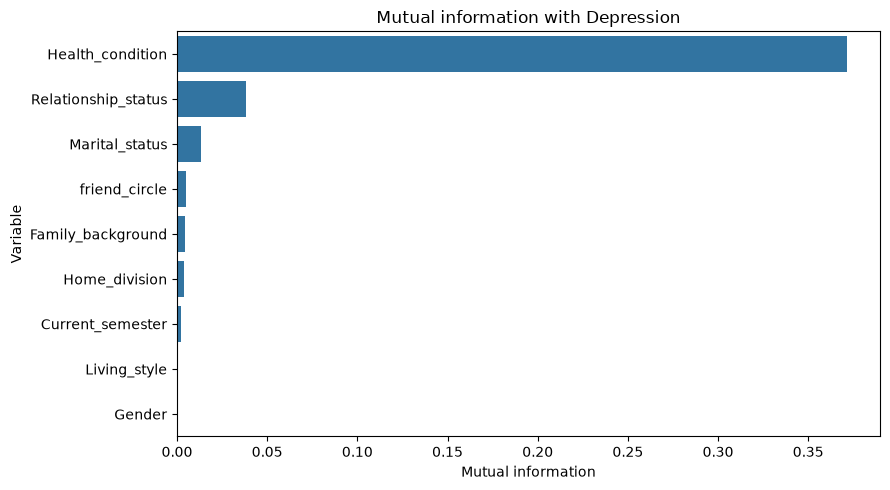

In [27]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=mi_table,
    x="Mutual_information",
    y="Variable",
    color="tab:blue"
)

plt.title("Mutual information with Depression")
plt.xlabel("Mutual information")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

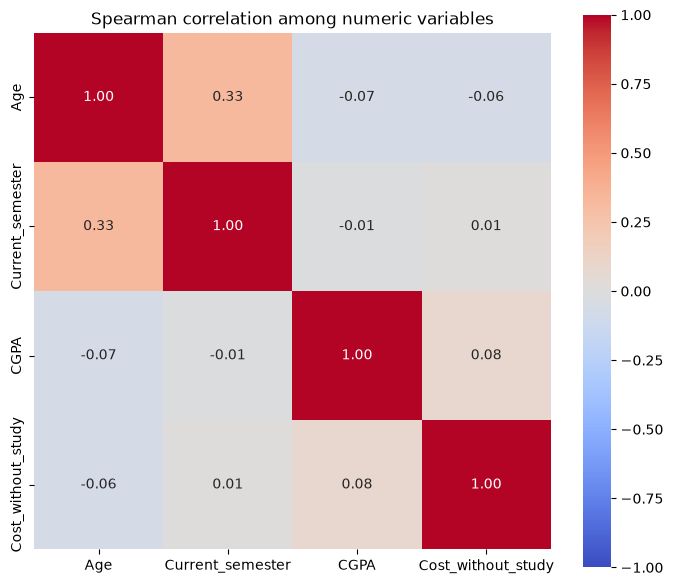

In [46]:
numeric_cols = ["Age", "Current_semester", "CGPA", "Cost_without_study"]

plt.figure(figsize=(7, 6))

sns.heatmap(
    df[numeric_cols].corr(method="pearson"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Spearman correlation among numeric variables")
plt.tight_layout()
plt.show()

In [33]:
display(df.loc[df["Age"] < 18])

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression,CGPA_group
72,Male,17,Lower Middle class,Single,Unmarried,Family,1,3.68,Yes,Good,3225,Mymensingh,No,>3.5
166,Female,17,Lower Middle class,Complicated,Unmarried,Bachelor,1,3.33,Yes,Good,9621,Rangpur,No,3.0-3.5
180,Male,17,Middle class,Single,Unmarried,Family,0,3.50,Yes,Abnormal,17272,Dhaka,Yes,3.0-3.5
199,Female,17,Lower Middle class,In a Relationship,Unmarried,Bachelor,3,3.90,Yes,Good,1880,Rangpur,No,>3.5
408,Female,17,Rich class,Single,Unmarried,Bachelor,1,3.58,Yes,Normal,27068,Khulna,No,>3.5
420,Female,17,Lower Middle class,In a Relationship,Unmarried,Family,4,4.00,Yes,Good,9033,Sylhet,No,>3.5
446,Female,17,Middle class,Single,Unmarried,Bachelor,1,3.50,No,Good,13455,Rangpur,No,3.0-3.5
600,Male,17,Lower Middle class,In a Relationship,Unmarried,Bachelor,2,3.50,No,Good,6474,Chittagong,No,3.0-3.5
3441,Male,17,Middle class,Single,Unmarried,Family,2,2.80,Yes,Abnormal,15000,Mymensingh,Yes,2.5-3.0
3464,Female,17,Lower Middle class,In a Relationship,Unmarried,Family,2,3.41,No,Critical,10000,Mymensingh,Yes,3.0-3.5


In [44]:
subset = df.loc[
    (df["Marital_status"] == "Married") &
    (df["Relationship_status"] == "Single")
]

display(subset.describe(include="all"))


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression,CGPA_group
count,201,201.000000,201,201,201,201,201.000000,201.000000,201,201,201.000000,201,201,201
unique,2,NaN,3,1,1,2,NaN,NaN,2,4,NaN,8,2,3
top,Male,NaN,Middle class,Single,Married,Bachelor,NaN,NaN,Yes,Normal,NaN,Khulna,No,>3.5
freq,123,NaN,127,201,201,140,NaN,NaN,132,66,NaN,52,153,108
mean,NaN,23.139303,NaN,NaN,NaN,NaN,5.885572,3.446915,NaN,NaN,14672.124378,NaN,NaN,NaN
std,NaN,2.360190,NaN,NaN,NaN,NaN,2.800329,0.355140,NaN,NaN,6818.869214,NaN,NaN,NaN
min,NaN,18.000000,NaN,NaN,NaN,NaN,0.000000,2.570000,NaN,NaN,134.000000,NaN,NaN,NaN
25%,NaN,21.000000,NaN,NaN,NaN,NaN,4.000000,3.000000,NaN,NaN,10703.000000,NaN,NaN,NaN
50%,NaN,23.000000,NaN,NaN,NaN,NaN,6.000000,3.550000,NaN,NaN,14687.000000,NaN,NaN,NaN
75%,NaN,25.000000,NaN,NaN,NaN,NaN,8.000000,3.750000,NaN,NaN,18436.000000,NaN,NaN,NaN


### ANALISI DEI PESI
???